Scoring equation: w1 * (public transit time/car transit time in minutes) + w2 * num departures + w3 * (1/earliest time rounded nearest .5h)

with w1 = 0.5, w2= 0.3 w3= 0.2

Here is our data collecting process:
1. Open google Maps
2. select arrival destination as EPFL for people who work in Lausanne and Epfl-valais for the people who work in Sion and departure destination as the commune
3. for each journey set the arrival time to 8 to collect the public and car transport time
4. scroll and find out how many departure times are possible (count)
5. set departure time at 6 and find out what the earliest arrival time is

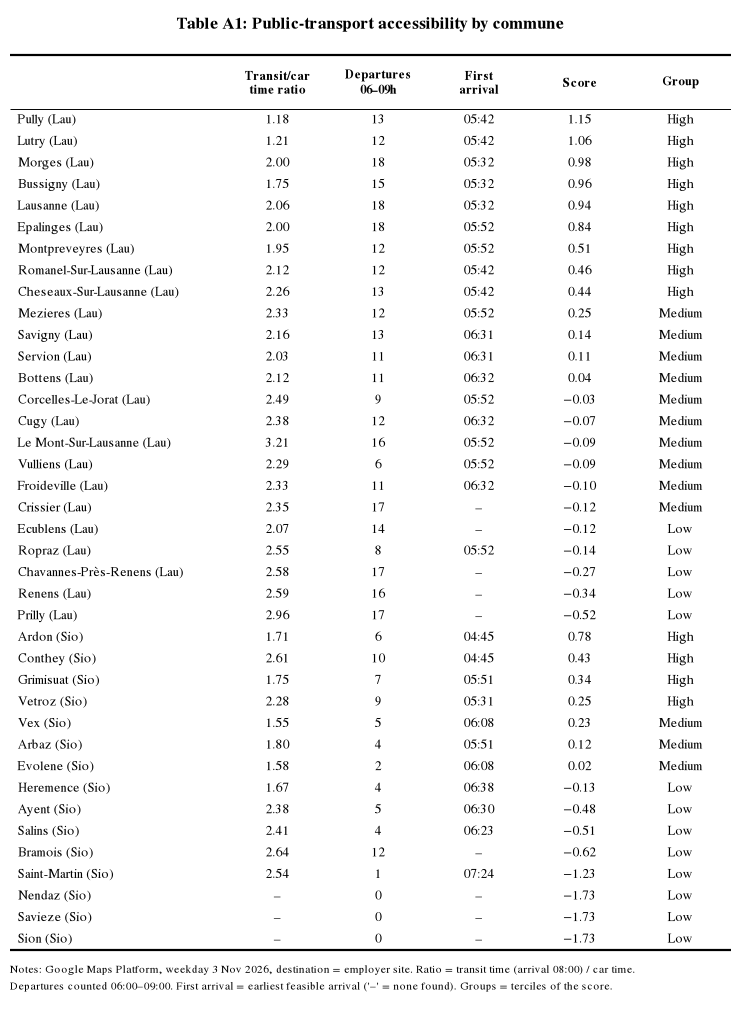

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})

t = pd.read_csv("transit_access.csv")

def booktabs(tab, title, fname, col_w=1.4, label_w=2.6, row_h=0.3, header_h=0.7,
             header_fs=9, body_fs=9.5, note=None):
    n_rows, n_cols = tab.shape
    widths = [col_w] * n_cols if np.isscalar(col_w) else list(col_w)
    xs = label_w + np.concatenate([[0], np.cumsum(widths)])
    width = xs[-1]
    height = header_h + row_h * n_rows + 1.3
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.6; body_top = top - header_h; bottom = body_top - row_h * n_rows
    for j, c in enumerate(tab.columns):
        ax.text((xs[j] + xs[j+1]) / 2, top - header_h / 2, c, ha="center", va="center",
                weight="bold", fontsize=header_fs, linespacing=1.1)
    for i, (lab, row) in enumerate(tab.iterrows()):
        y = body_top - row_h * (i + 0.5)
        ax.text(0.1, y, lab, ha="left", va="center", fontsize=body_fs)
        for j, v in enumerate(row):
            ax.text((xs[j] + xs[j+1]) / 2, y, str(v), ha="center", va="center", fontsize=body_fs)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(body_top, 0, width, color="black", lw=0.7)
    ax.hlines(bottom, 0, width, color="black", lw=1.6)
    ax.text(width / 2, height - 0.2, title, ha="center", va="center", fontsize=12, weight="bold")
    if note:
        ax.text(0, bottom - 0.15, note, ha="left", va="top", fontsize=8)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

A1 = t.sort_values(["site", "transit_score"], ascending=[True, False]).copy()
A1["lab"] = A1["home_commune"] + " (" + A1["site"].str[:3] + ")"
A1 = A1.set_index("lab")
A1 = pd.DataFrame({
    "Transit/car\ntime ratio": A1["transit_ratio"].map(lambda v: "–" if pd.isna(v) else f"{v:.2f}"),
    "Departures\n06–09h": A1["departures_0600_0900"].astype(int).astype(str),
    "First\narrival": A1["first_arrival_time"].fillna("–"),
    "Score": A1["transit_score"].map(lambda v: f"{v:.2f}".replace("-", "−")),
    "Group": A1["transit_group"],
})
A1.index.name = None

booktabs(A1, "Table A1: Public-transport accessibility by commune", "table_A1.png",
         col_w=1.3, label_w=2.8, row_h=0.28,
         note=("Notes: Google Maps Platform, weekday 3 Nov 2026, destination = employer site. "
               "Ratio = transit time (arrival 08:00) / car time.\n"
               "Departures counted 06:00–09:00. First arrival = earliest feasible arrival "
               "('–' = none found). Groups = terciles of the score."))